In [1]:
!pip install pandas pillow tqdm matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\ASUS\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path

DATASET_DIR = Path(r"D:\code material 2.0\akshar-setu-v2\data\words\train\train")

IMAGE_DIR = DATASET_DIR / "images"
GT_FILE = DATASET_DIR / "train_gt.txt"
VOCAB_FILE = DATASET_DIR / "vocabulary.txt"

print("Dataset:", DATASET_DIR)
print("Images:", IMAGE_DIR)
print("Ground Truth:", GT_FILE)
print("Vocabulary:", VOCAB_FILE)

Dataset: D:\code material 2.0\akshar-setu-v2\data\words\train\train
Images: D:\code material 2.0\akshar-setu-v2\data\words\train\train\images
Ground Truth: D:\code material 2.0\akshar-setu-v2\data\words\train\train\train_gt.txt
Vocabulary: D:\code material 2.0\akshar-setu-v2\data\words\train\train\vocabulary.txt


In [3]:
print("Dataset folder exists :", DATASET_DIR.exists())
print("Images folder exists  :", IMAGE_DIR.exists())
print("GT file exists        :", GT_FILE.exists())
print("Vocabulary exists     :", VOCAB_FILE.exists())

Dataset folder exists : True
Images folder exists  : True
GT file exists        : True
Vocabulary exists     : True


In [4]:
from tqdm import tqdm

image_files = list(IMAGE_DIR.rglob("*"))

image_files = [
    p for p in image_files
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"]
]

print("Total image files:", len(image_files))

Total image files: 79910


In [5]:
with open(GT_FILE, "r", encoding="utf-8") as f:
    gt_lines = f.readlines()

print("Total GT lines:", len(gt_lines))

print("\nFirst 10 entries:\n")

for line in gt_lines[:10]:
    print(repr(line))

Total GT lines: 79910

First 10 entries:

'images/0088-0056_2_10_1.jpeg\tઅમે\n'
'images/0088-0056_2_10_2.jpeg\tજીવી\n'
'images/0088-0056_2_10_3.jpeg\tશકીશું\n'
'images/0088-0056_2_10_4.jpeg\tનહિ.\n'
'images/0088-0056_2_10_5.jpeg\tફૂલ\n'
'images/0088-0056_2_10_6.jpeg\tઅને\n'
'images/0088-0056_2_10_7.jpeg\tપાન\n'
'images/0088-0056_2_10_8.jpeg\tવિનાના\n'
'images/0088-0056_2_10_9.jpeg\tછોડ\n'
'images/0088-0056_2_10_10.jpeg\tજેવી\n'


In [6]:
records = []

for line in gt_lines:
    line = line.strip()

    if not line:
        continue

    parts = line.split(maxsplit=1)

    if len(parts) == 2:
        image_path, text = parts
        records.append((image_path, text))

print("Parsed records:", len(records))

print("\nFirst 10 records:\n")

for record in records[:10]:
    print(record)

Parsed records: 79910

First 10 records:

('images/0088-0056_2_10_1.jpeg', 'અમે')
('images/0088-0056_2_10_2.jpeg', 'જીવી')
('images/0088-0056_2_10_3.jpeg', 'શકીશું')
('images/0088-0056_2_10_4.jpeg', 'નહિ.')
('images/0088-0056_2_10_5.jpeg', 'ફૂલ')
('images/0088-0056_2_10_6.jpeg', 'અને')
('images/0088-0056_2_10_7.jpeg', 'પાન')
('images/0088-0056_2_10_8.jpeg', 'વિનાના')
('images/0088-0056_2_10_9.jpeg', 'છોડ')
('images/0088-0056_2_10_10.jpeg', 'જેવી')


In [7]:
malformed = []

for i, line in enumerate(gt_lines, start=1):
    line = line.strip()

    if not line:
        continue

    parts = line.split(maxsplit=1)

    if len(parts) != 2:
        malformed.append((i, line))

print("Malformed lines:", len(malformed))

if malformed:
    print("\nFirst 10 malformed lines:")
    for item in malformed[:10]:
        print(item)

Malformed lines: 0


In [8]:
missing_images = []

for image_path, text in tqdm(records):
    full_path = DATASET_DIR / image_path

    if not full_path.exists():
        missing_images.append(image_path)

print("\nMissing images:", len(missing_images))

if missing_images:
    print("\nFirst 20 missing images:")
    for path in missing_images[:20]:
        print(path)

100%|██████████| 79910/79910 [00:03<00:00, 22495.23it/s]


Missing images: 0


In [9]:
empty_labels = [
    (image_path, text)
    for image_path, text in records
    if not text.strip()
]

print("Empty labels:", len(empty_labels))

if empty_labels:
    print(empty_labels[:20])

Empty labels: 0


In [10]:
import unicodedata

different_normalization = []

for image_path, text in records:
    normalized = unicodedata.normalize("NFC", text)

    if text != normalized:
        different_normalization.append(
            (image_path, text, normalized)
        )

print("Labels needing NFC normalization:", len(different_normalization))

if different_normalization:
    print("\nExamples:")
    for item in different_normalization[:10]:
        print(item)

Labels needing NFC normalization: 0


C:\Users\ASUS\AppData\Local\Temp\ipykernel_7512\2893766642.py:17: UserWarning: Glyph 2693 (\N{GUJARATI LETTER A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_7512\2893766642.py:17: UserWarning: Glyph 2734 (\N{GUJARATI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_7512\2893766642.py:17: UserWarning: Glyph 2716 (\N{GUJARATI LETTER JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_7512\2893766642.py:17: UserWarning: Glyph 2741 (\N{GUJARATI LETTER VA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_7512\2893766642.py:17: UserWarning: Glyph 2742 (\N{GUJARATI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_7512\2893766642.py:17: UserWarning: Glyph 2709 (\N{GUJARATI LETTER KA}) missing from font(s) DejaVu Sans.
 

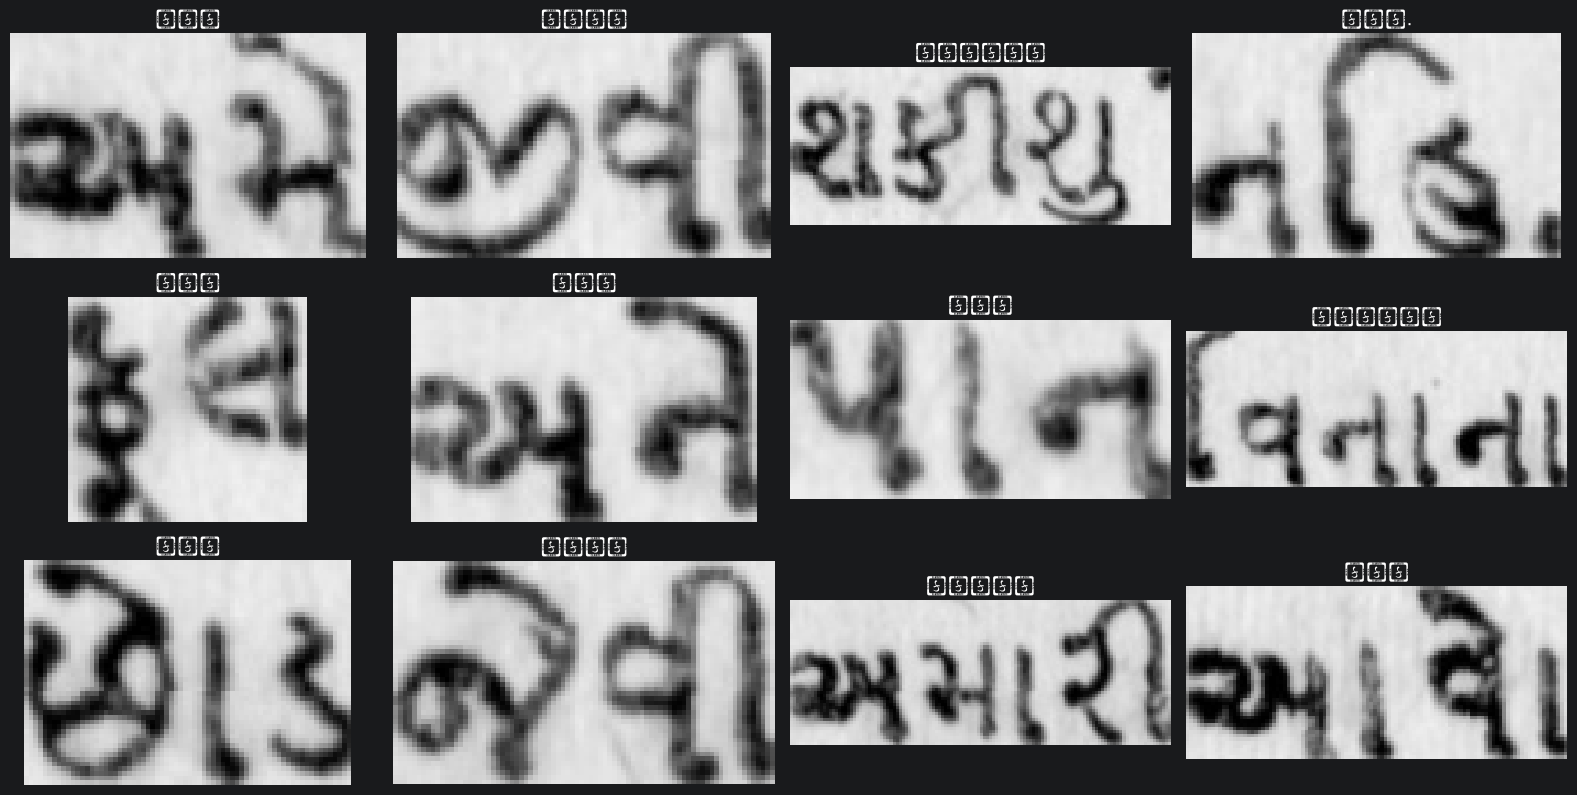

In [11]:
from PIL import Image
import matplotlib.pyplot as plt

sample_records = records[:12]

fig, axes = plt.subplots(3, 4, figsize=(16, 8))

for ax, (image_path, text) in zip(axes.ravel(), sample_records):
    full_path = DATASET_DIR / image_path

    image = Image.open(full_path)

    ax.imshow(image, cmap="gray")
    ax.set_title(text, fontsize=14)
    ax.axis("off")

plt.tight_layout()
plt.show()

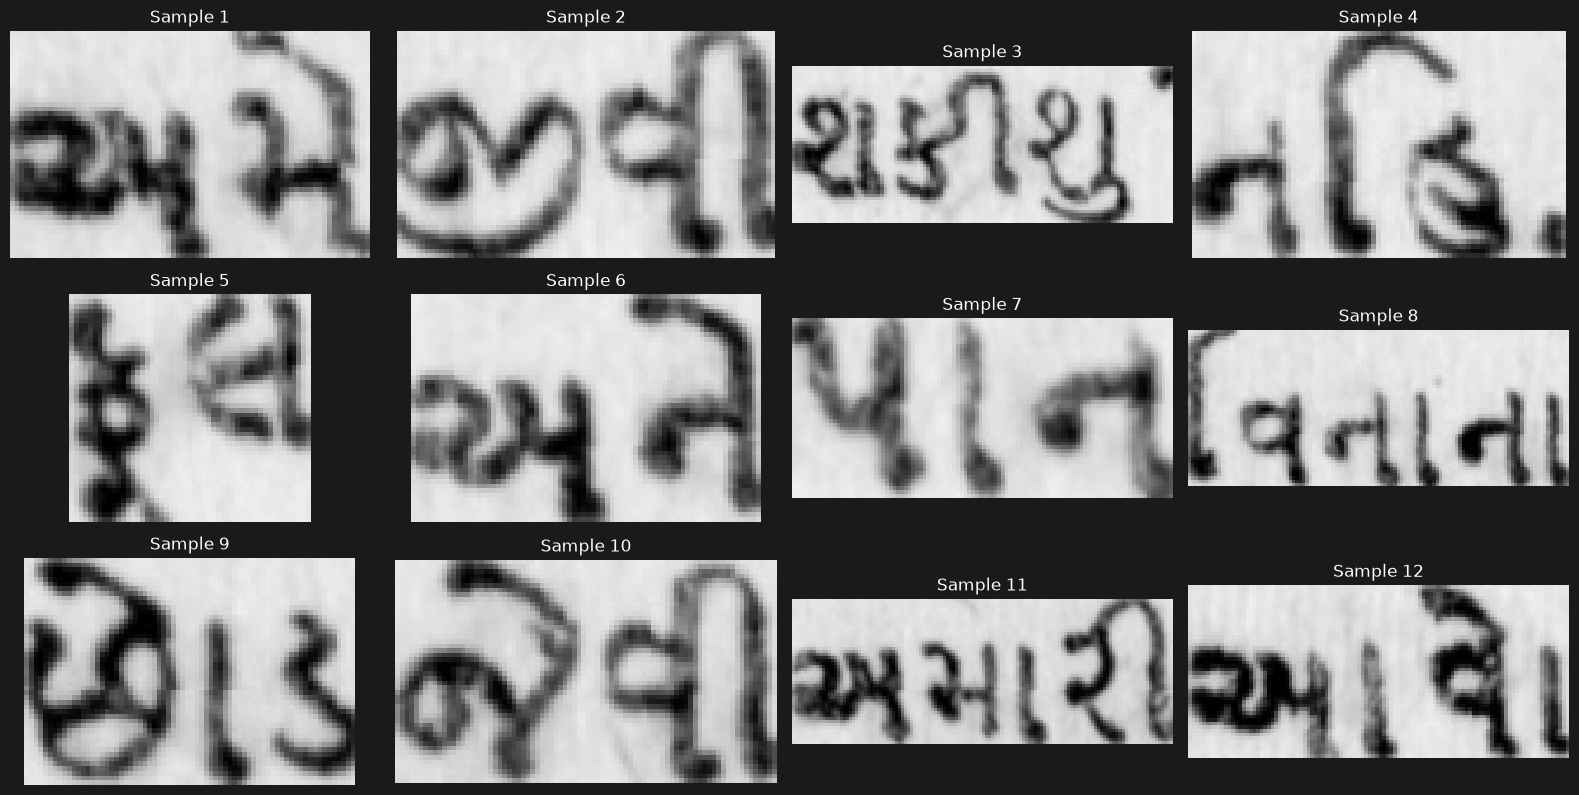


IMAGE → GROUND TRUTH
1. images/0088-0056_2_10_1.jpeg
   Gujarati: અમે

2. images/0088-0056_2_10_2.jpeg
   Gujarati: જીવી

3. images/0088-0056_2_10_3.jpeg
   Gujarati: શકીશું

4. images/0088-0056_2_10_4.jpeg
   Gujarati: નહિ.

5. images/0088-0056_2_10_5.jpeg
   Gujarati: ફૂલ

6. images/0088-0056_2_10_6.jpeg
   Gujarati: અને

7. images/0088-0056_2_10_7.jpeg
   Gujarati: પાન

8. images/0088-0056_2_10_8.jpeg
   Gujarati: વિનાના

9. images/0088-0056_2_10_9.jpeg
   Gujarati: છોડ

10. images/0088-0056_2_10_10.jpeg
   Gujarati: જેવી

11. images/0088-0056_2_10_11.jpeg
   Gujarati: અમારી

12. images/0088-0056_3_20_1.jpeg
   Gujarati: આવો



In [12]:
from PIL import Image
import matplotlib.pyplot as plt

sample_records = records[:12]

fig, axes = plt.subplots(3, 4, figsize=(16, 8))

for i, (ax, (image_path, text)) in enumerate(zip(axes.ravel(), sample_records)):
    full_path = DATASET_DIR / image_path

    image = Image.open(full_path)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Sample {i+1}", fontsize=12)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("IMAGE → GROUND TRUTH")
print("=" * 60)

for i, (image_path, text) in enumerate(sample_records, start=1):
    print(f"{i}. {image_path}")
    print(f"   Gujarati: {text}")
    print()

In [13]:
import pandas as pd
import unicodedata

data = []

for image_path, text in records:
    normalized_text = unicodedata.normalize("NFC", text)

    data.append({
        "image_path": image_path,
        "text": normalized_text
    })

df = pd.DataFrame(data)

print("Total records:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 10 records:")
display(df.head(10))

Total records: 79910

Columns:
['image_path', 'text']

First 10 records:


,image_path,text
0,images/0088-0056_2_10_1.jpeg,અમે
1,images/0088-0056_2_10_2.jpeg,જીવી
2,images/0088-0056_2_10_3.jpeg,શકીશું
3,images/0088-0056_2_10_4.jpeg,નહિ.
4,images/0088-0056_2_10_5.jpeg,ફૂલ
5,images/0088-0056_2_10_6.jpeg,અને
6,images/0088-0056_2_10_7.jpeg,પાન
7,images/0088-0056_2_10_8.jpeg,વિનાના
8,images/0088-0056_2_10_9.jpeg,છોડ
9,images/0088-0056_2_10_10.jpeg,જેવી


In [14]:
df["text_length"] = df["text"].str.len()

print("Total images:", len(df))
print("Unique image paths:", df["image_path"].nunique())
print("Unique words:", df["text"].nunique())

print("\nWord length statistics:")
print(df["text_length"].describe())

Total images: 79910
Unique image paths: 79910
Unique words: 23800

Word length statistics:
count    79910.000000
mean         4.717382
std          2.370350
min          1.000000
25%          3.000000
50%          4.000000
75%          6.000000
max         42.000000
Name: text_length, dtype: float64


In [15]:
duplicate_paths = df[df["image_path"].duplicated(keep=False)]

print("Duplicate image paths:", len(duplicate_paths))

if len(duplicate_paths) > 0:
    display(
        duplicate_paths
        .sort_values("image_path")
        .head(20)
    )

Duplicate image paths: 0


In [16]:
word_counts = df["text"].value_counts()

print("Unique Gujarati words:", len(word_counts))

print("\nMost frequent words:")
display(word_counts.head(20))

Unique Gujarati words: 23800

Most frequent words:


text
અને     1279
પણ      1038
તો       900
જ        874
આ        797
છે.      774
તે       727
છે       714
કે       689
એ        662
ન        492
એક       451
હું      403
માટે     367
ને       362
મને      320
કરી      274
થઈ       258
હતો.     250
હોય      245
Name: count, dtype: int64

In [17]:
df["filename"] = df["image_path"].apply(
    lambda x: Path(x).name
)

df["stem"] = df["filename"].apply(
    lambda x: Path(x).stem
)

print(df[["image_path", "filename", "stem"]].head(20))

                       image_path                filename               stem
0    images/0088-0056_2_10_1.jpeg   0088-0056_2_10_1.jpeg   0088-0056_2_10_1
1    images/0088-0056_2_10_2.jpeg   0088-0056_2_10_2.jpeg   0088-0056_2_10_2
2    images/0088-0056_2_10_3.jpeg   0088-0056_2_10_3.jpeg   0088-0056_2_10_3
3    images/0088-0056_2_10_4.jpeg   0088-0056_2_10_4.jpeg   0088-0056_2_10_4
4    images/0088-0056_2_10_5.jpeg   0088-0056_2_10_5.jpeg   0088-0056_2_10_5
5    images/0088-0056_2_10_6.jpeg   0088-0056_2_10_6.jpeg   0088-0056_2_10_6
6    images/0088-0056_2_10_7.jpeg   0088-0056_2_10_7.jpeg   0088-0056_2_10_7
7    images/0088-0056_2_10_8.jpeg   0088-0056_2_10_8.jpeg   0088-0056_2_10_8
8    images/0088-0056_2_10_9.jpeg   0088-0056_2_10_9.jpeg   0088-0056_2_10_9
9   images/0088-0056_2_10_10.jpeg  0088-0056_2_10_10.jpeg  0088-0056_2_10_10
10  images/0088-0056_2_10_11.jpeg  0088-0056_2_10_11.jpeg  0088-0056_2_10_11
11   images/0088-0056_3_20_1.jpeg   0088-0056_3_20_1.jpeg   0088-0056_3_20_1

In [18]:
example = df["stem"].iloc[0]

print("Example:", example)

parts = example.split("_")

print("Parts:")
for i, part in enumerate(parts):
    print(i, "->", part)

Example: 0088-0056_2_10_1
Parts:
0 -> 0088-0056
1 -> 2
2 -> 10
3 -> 1


In [19]:
df["source_id"] = df["stem"].str.split("_").str[0]

print("Unique source IDs:", df["source_id"].nunique())

print("\nImages per source:")
display(
    df["source_id"]
    .value_counts()
    .describe()
)

Unique source IDs: 3365

Images per source:


count    3365.0000
mean       23.7474
std        12.0344
min         1.0000
25%        15.0000
50%        23.0000
75%        32.0000
max        72.0000
Name: count, dtype: float64

In [20]:
print("\nTop 20 source IDs:")
display(df["source_id"].value_counts().head(20))


Top 20 source IDs:


source_id
0082-0127    72
0082-0070    70
0082-0057    69
0082-0041    68
0082-0018    63
0082-0107    61
0082-0106    60
0082-0089    59
0098-0455    58
0096-0120    58
0082-0157    58
0082-0091    58
0082-0054    58
0098-0018    57
0082-0051    57
0082-0024    57
0082-0142    56
0082-0064    56
0096-0116    55
0082-0088    55
Name: count, dtype: int64

In [21]:
source_counts = df["source_id"].value_counts()

print("Total source groups:", len(source_counts))
print("Total images:", source_counts.sum())

print("\nImages per source statistics:")
print(source_counts.describe())

Total source groups: 3365
Total images: 79910

Images per source statistics:
count    3365.0000
mean       23.7474
std        12.0344
min         1.0000
25%        15.0000
50%        23.0000
75%        32.0000
max        72.0000
Name: count, dtype: float64


In [22]:
print("TOP 20 LARGEST SOURCE GROUPS")
print("=" * 60)

display(
    source_counts.head(20).to_frame("image_count")
)

TOP 20 LARGEST SOURCE GROUPS


,image_count
source_id,
0082-0127,72
0082-0070,70
0082-0057,69
0082-0041,68
0082-0018,63
0082-0107,61
0082-0106,60
0082-0089,59
0098-0455,58


In [23]:
print("\nSMALLEST 20 SOURCE GROUPS")
print("=" * 60)

display(
    source_counts.tail(20).to_frame("image_count")
)


SMALLEST 20 SOURCE GROUPS


,image_count
source_id,
0081-0112,1
0082-0102,1
0081-0167,1
0082-0124,1
0079-0021,1
0098-0285,1
0098-0107,1
0098-0173,1
0098-0049,1


In [24]:
for source_id in df["source_id"].drop_duplicates().head(10):

    subset = df[df["source_id"] == source_id]

    print("\n" + "=" * 70)
    print("SOURCE:", source_id)
    print("NUMBER OF IMAGES:", len(subset))
    print("=" * 70)

    display(
        subset[
            ["image_path", "text"]
        ].head(15)
    )


SOURCE: 0088-0056
NUMBER OF IMAGES: 22


,image_path,text
0,images/0088-0056_2_10_1.jpeg,અમે
1,images/0088-0056_2_10_2.jpeg,જીવી
2,images/0088-0056_2_10_3.jpeg,શકીશું
3,images/0088-0056_2_10_4.jpeg,નહિ.
4,images/0088-0056_2_10_5.jpeg,ફૂલ
5,images/0088-0056_2_10_6.jpeg,અને
6,images/0088-0056_2_10_7.jpeg,પાન
7,images/0088-0056_2_10_8.jpeg,વિનાના
8,images/0088-0056_2_10_9.jpeg,છોડ
9,images/0088-0056_2_10_10.jpeg,જેવી



SOURCE: 0088-0334
NUMBER OF IMAGES: 8


,image_path,text
22,images/0088-0334_3_10_1.jpeg,હું
23,images/0088-0334_3_10_2.jpeg,મારી
24,images/0088-0334_3_10_3.jpeg,બેનપણીઓને
25,images/0088-0334_3_10_4.jpeg,કે
26,images/0088-0334_3_10_5.jpeg,મારાં
27,images/0088-0334_3_10_6.jpeg,સગાંઓને
28,images/0088-0334_3_10_7.jpeg,સંકોચ
29,images/0088-0334_3_10_8.jpeg,વિના



SOURCE: 0088-0445
NUMBER OF IMAGES: 31


...

,image_path,text
180,images/0088-0375_3_3_1.jpeg,વહાલાં
181,images/0088-0375_3_3_2.jpeg,"ભાઈ-બેહન,"
182,images/0088-0375_5_10_1.jpeg,મારે
183,images/0088-0375_5_10_2.jpeg,જે
184,images/0088-0375_5_10_3.jpeg,કહેવું
185,images/0088-0375_5_10_4.jpeg,છે
186,images/0088-0375_5_10_5.jpeg,તે
187,images/0088-0375_5_10_6.jpeg,તો
188,images/0088-0375_5_10_7.jpeg,કહેવું
189,images/0088-0375_5_10_8.jpeg,જ



SOURCE: 0088-0280
NUMBER OF IMAGES: 22


,image_path,text
207,images/0088-0280_2_3_1.jpeg,કોઈ
208,images/0088-0280_2_3_2.jpeg,તરફ
209,images/0088-0280_2_3_3.jpeg,ઢળે
210,images/0088-0280_2_3_4.jpeg,તો
211,images/0088-0280_2_3_5.jpeg,ભાભી
212,images/0088-0280_2_3_6.jpeg,પાસે
213,images/0088-0280_2_3_7.jpeg,પ્રગટ
214,images/0088-0280_2_3_8.jpeg,કરતાં
215,images/0088-0280_2_3_9.jpeg,એને
216,images/0088-0280_2_3_10.jpeg,સંકોચ



SOURCE: 0088-0353
NUMBER OF IMAGES: 19


,image_path,text
229,images/0088-0353_2_3_1.jpeg,પહેલા
230,images/0088-0353_2_3_2.jpeg,દિવસથી
231,images/0088-0353_2_3_3.jpeg,જ
232,images/0088-0353_2_3_4.jpeg,નહિ.
233,images/0088-0353_2_3_5.jpeg,લગ્ન
234,images/0088-0353_2_3_6.jpeg,વખતથી
235,images/0088-0353_2_3_7.jpeg,જ
236,images/0088-0353_2_3_8.jpeg,શરૂ
237,images/0088-0353_2_3_9.jpeg,થઈ
238,images/0088-0353_2_3_10.jpeg,જાય


In [25]:
word_counts = df["text"].value_counts()

print("Total word images:", len(df))
print("Unique words:", len(word_counts))

print("\nFrequency distribution:")
print(word_counts.describe())

Total word images: 79910
Unique words: 23800

Frequency distribution:
count    23800.000000
mean         3.357563
std         21.154921
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max       1279.000000
Name: count, dtype: float64


In [26]:
print("\nWords appearing only once:")
print((word_counts == 1).sum())

print("Words appearing 2 times:")
print((word_counts == 2).sum())

print("Words appearing 3 times:")
print((word_counts == 3).sum())

print("Words appearing 10+ times:")
print((word_counts >= 10).sum())


Words appearing only once:
16597
Words appearing 2 times:
3065
Words appearing 3 times:
1220
Words appearing 10+ times:
1047


In [27]:
df["group_id"] = (
    df["stem"]
    .str.rsplit("_", n=1)
    .str[0]
)

print("Unique groups:", df["group_id"].nunique())

print("\nExample groups:")
display(
    df[
        ["image_path", "group_id", "text"]
    ].head(25)
)

Unique groups: 8701

Example groups:


,image_path,group_id,text
0,images/0088-0056_2_10_1.jpeg,0088-0056_2_10,અમે
1,images/0088-0056_2_10_2.jpeg,0088-0056_2_10,જીવી
2,images/0088-0056_2_10_3.jpeg,0088-0056_2_10,શકીશું
3,images/0088-0056_2_10_4.jpeg,0088-0056_2_10,નહિ.
4,images/0088-0056_2_10_5.jpeg,0088-0056_2_10,ફૂલ
5,images/0088-0056_2_10_6.jpeg,0088-0056_2_10,અને
6,images/0088-0056_2_10_7.jpeg,0088-0056_2_10,પાન
7,images/0088-0056_2_10_8.jpeg,0088-0056_2_10,વિનાના
8,images/0088-0056_2_10_9.jpeg,0088-0056_2_10,છોડ
9,images/0088-0056_2_10_10.jpeg,0088-0056_2_10,જેવી


In [28]:
group_counts = df["group_id"].value_counts()

print("Total groups:", len(group_counts))
print("Total images:", group_counts.sum())

print("\nGroup size statistics:")
print(group_counts.describe())

Total groups: 8701
Total images: 79910

Group size statistics:
count    8701.000000
mean        9.184002
std         3.425771
min         1.000000
25%         7.000000
50%        10.000000
75%        12.000000
max        19.000000
Name: count, dtype: float64


In [29]:
example_group = df["group_id"].iloc[0]

print("Example group:", example_group)

group_df = df[df["group_id"] == example_group]

display(
    group_df[
        ["image_path", "text"]
    ]
)

Example group: 0088-0056_2_10


,image_path,text
0,images/0088-0056_2_10_1.jpeg,અમે
1,images/0088-0056_2_10_2.jpeg,જીવી
2,images/0088-0056_2_10_3.jpeg,શકીશું
3,images/0088-0056_2_10_4.jpeg,નહિ.
4,images/0088-0056_2_10_5.jpeg,ફૂલ
5,images/0088-0056_2_10_6.jpeg,અને
6,images/0088-0056_2_10_7.jpeg,પાન
7,images/0088-0056_2_10_8.jpeg,વિનાના
8,images/0088-0056_2_10_9.jpeg,છોડ
9,images/0088-0056_2_10_10.jpeg,જેવી


In [30]:
print("Images:", len(df))
print("Unique groups:", df["group_id"].nunique())
print(
    "Average images per group:",
    len(df) / df["group_id"].nunique()
)

Images: 79910
Unique groups: 8701
Average images per group: 9.184001838869095


In [31]:
print("Group size distribution:")
display(
    group_counts
    .value_counts()
    .sort_index()
    .to_frame("number_of_groups")
)

print("\nMinimum group size:", group_counts.min())
print("Maximum group size:", group_counts.max())
print("Median group size:", group_counts.median())

Group size distribution:


,number_of_groups
count,
1,259
2,221
3,263
4,350
5,374
6,378
7,456
8,642
9,969



Minimum group size: 1
Maximum group size: 19
Median group size: 10.0


In [32]:
!pip install scikit-learn


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\ASUS\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [34]:
from sklearn.model_selection import GroupShuffleSplit

# First split:
# 80% TRAIN
# 20% temporary (will become validation + test)

gss_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, temp_idx = next(
    gss_1.split(
        df,
        groups=df["group_id"]
    )
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

print("Train images:", len(train_df))
print("Temporary images:", len(temp_df))

print("Train groups:", train_df["group_id"].nunique())
print("Temporary groups:", temp_df["group_id"].nunique())

Train images: 63924
Temporary images: 15986
Train groups: 6960
Temporary groups: 1741


In [35]:
# Split the remaining 20% equally:
# 10% VALIDATION
# 10% TEST

gss_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss_2.split(
        temp_df,
        groups=temp_df["group_id"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print("TRAIN:")
print("Images:", len(train_df))
print("Groups:", train_df["group_id"].nunique())

print("\nVALIDATION:")
print("Images:", len(val_df))
print("Groups:", val_df["group_id"].nunique())

print("\nTEST:")
print("Images:", len(test_df))
print("Groups:", test_df["group_id"].nunique())

TRAIN:
Images: 63924
Groups: 6960

VALIDATION:
Images: 7928
Groups: 870

TEST:
Images: 8058
Groups: 871


In [36]:
train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])
test_groups = set(test_df["group_id"])

print("Train ∩ Validation:", len(train_groups & val_groups))
print("Train ∩ Test:", len(train_groups & test_groups))
print("Validation ∩ Test:", len(val_groups & test_groups))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [37]:
total = len(train_df) + len(val_df) + len(test_df)

print(f"Total images: {total}")

print(
    f"Train:      {len(train_df):,} "
    f"({len(train_df)/total*100:.2f}%)"
)

print(
    f"Validation: {len(val_df):,} "
    f"({len(val_df)/total*100:.2f}%)"
)

print(
    f"Test:       {len(test_df):,} "
    f"({len(test_df)/total*100:.2f}%)"
)

Total images: 79910
Train:      63,924 (79.99%)
Validation: 7,928 (9.92%)
Test:       8,058 (10.08%)


In [38]:
print("Unique words:")
print("Train:", train_df["text"].nunique())
print("Validation:", val_df["text"].nunique())
print("Test:", test_df["text"].nunique())

Unique words:
Train: 20350
Validation: 4234
Test: 4247


save the dataset

In [39]:
SPLIT_DIR = DATASET_DIR / "splits"
SPLIT_DIR.mkdir(exist_ok=True)

train_csv = SPLIT_DIR / "train.csv"
val_csv = SPLIT_DIR / "validation.csv"
test_csv = SPLIT_DIR / "test.csv"

train_df[
    ["image_path", "text"]
].to_csv(
    train_csv,
    index=False,
    encoding="utf-8-sig"
)

val_df[
    ["image_path", "text"]
].to_csv(
    val_csv,
    index=False,
    encoding="utf-8-sig"
)

test_df[
    ["image_path", "text"]
].to_csv(
    test_csv,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:")
print(train_csv)
print(val_csv)
print(test_csv)

Saved:
D:\code material 2.0\akshar-setu-v2\data\words\train\train\splits\train.csv
D:\code material 2.0\akshar-setu-v2\data\words\train\train\splits\validation.csv
D:\code material 2.0\akshar-setu-v2\data\words\train\train\splits\test.csv


Prepare the word dataset for TrOCR

Cell 43 — Load the three CSV files

In [40]:
import pandas as pd
from pathlib import Path

train_df = pd.read_csv(
    DATASET_DIR / "splits" / "train.csv",
    encoding="utf-8-sig"
)

val_df = pd.read_csv(
    DATASET_DIR / "splits" / "validation.csv",
    encoding="utf-8-sig"
)

test_df = pd.read_csv(
    DATASET_DIR / "splits" / "test.csv",
    encoding="utf-8-sig"
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 63924
Validation: 7928
Test: 8058


In [41]:
import unicodedata

def normalize_gujarati(text):
    text = str(text)
    return unicodedata.normalize("NFC", text).strip()

train_df["text"] = train_df["text"].apply(normalize_gujarati)
val_df["text"] = val_df["text"].apply(normalize_gujarati)
test_df["text"] = test_df["text"].apply(normalize_gujarati)

print(train_df.head())

                     image_path   text
0  images/0088-0056_3_20_1.jpeg    આવો
1  images/0088-0056_3_20_2.jpeg    છો,
2  images/0088-0056_3_20_3.jpeg   અમને
3  images/0088-0056_3_20_4.jpeg   મળવા
4  images/0088-0056_3_20_5.jpeg  માટે.


In [42]:
from collections import Counter

all_text = "".join(train_df["text"].tolist())

char_counts = Counter(all_text)

print("Unique characters:", len(char_counts))

print("\nCharacters:")
for char, count in char_counts.most_common():
    print(repr(char), ":", count)

Unique characters: 131

Characters:
'ા' : 31353
'ે' : 18766
'ર' : 17275
'ન' : 15926
'ી' : 13840
'ત' : 13056
'્' : 12227
'ં' : 12089
'મ' : 11913
'ો' : 10780
'વ' : 10589
'ક' : 10048
'પ' : 7358
'ય' : 7330
'ુ' : 7125
'સ' : 6867
'જ' : 6564
'હ' : 6181
'.' : 5828
'લ' : 5757
'િ' : 4915
'દ' : 4082
'ગ' : 3978
'બ' : 3491
'ણ' : 3455
'થ' : 3398
'શ' : 3127
'આ' : 3077
'એ' : 3073
'અ' : 2848
'છ' : 2711
'ભ' : 2540
'ધ' : 2344
'ડ' : 2241
',' : 2239
'ચ' : 2170
'ટ' : 2120
'ઈ' : 2001
'ખ' : 1981
'ળ' : 1773
'ૂ' : 1702
'ષ' : 1014
"'" : 761
'ઓ' : 753
'ફ' : 707
'ઉ' : 654
'"' : 654
'ઠ' : 598
'ઘ' : 544
'-' : 397
'?' : 378
'૧' : 372
'।' : 303
'ૃ' : 296
'ઝ' : 284
'!' : 281
'ૈ' : 279
'ઊ' : 249
'૨' : 230
'ઃ' : 226
'ઢ' : 215
':' : 176
'ૌ' : 167
')' : 155
'(' : 154
'ઇ' : 153
'૯' : 151
'૦' : 146
'ૉ' : 128
'૪' : 124
'૩' : 117
'૫' : 107
';' : 106
'૮' : 95
'૬' : 95
'૭' : 92
'ઞ' : 85
'|' : 54
'ૅ' : 46
'ઑ' : 32
'”' : 30
'“' : 29
'1' : 18
'ઋ' : 16
'2' : 10
'/' : 8
'5' : 7
'ૠ' : 7
'0' : 7
'ઔ' : 7
'ઍ' : 7
'3' : 6
'4' : 6
'6' : 5


In [43]:
unicode_chars = sorted(set(all_text))

print("Total unique Unicode characters:", len(unicode_chars))

for char in unicode_chars:
    print(
        f"{char} -> U+{ord(char):04X} -> {unicodedata.name(char, 'UNKNOWN')}"
    )

Total unique Unicode characters: 131
! -> U+0021 -> EXCLAMATION MARK
" -> U+0022 -> QUOTATION MARK
' -> U+0027 -> APOSTROPHE
( -> U+0028 -> LEFT PARENTHESIS
) -> U+0029 -> RIGHT PARENTHESIS
, -> U+002C -> COMMA
- -> U+002D -> HYPHEN-MINUS
. -> U+002E -> FULL STOP
/ -> U+002F -> SOLIDUS
0 -> U+0030 -> DIGIT ZERO
1 -> U+0031 -> DIGIT ONE
2 -> U+0032 -> DIGIT TWO
3 -> U+0033 -> DIGIT THREE
4 -> U+0034 -> DIGIT FOUR
5 -> U+0035 -> DIGIT FIVE
6 -> U+0036 -> DIGIT SIX
7 -> U+0037 -> DIGIT SEVEN
8 -> U+0038 -> DIGIT EIGHT
9 -> U+0039 -> DIGIT NINE
: -> U+003A -> COLON
; -> U+003B -> SEMICOLON
? -> U+003F -> QUESTION MARK
B -> U+0042 -> LATIN CAPITAL LETTER B
` -> U+0060 -> GRAVE ACCENT
l -> U+006C -> LATIN SMALL LETTER L
y -> U+0079 -> LATIN SMALL LETTER Y
| -> U+007C -> VERTICAL LINE
ं -> U+0902 -> DEVANAGARI SIGN ANUSVARA
इ -> U+0907 -> DEVANAGARI LETTER I
क -> U+0915 -> DEVANAGARI LETTER KA
ख -> U+0916 -> DEVANAGARI LETTER KHA
ग -> U+0917 -> DEVANAGARI LETTER GA
ज -> U+091C -> DEVANAGARI L

In [44]:
unusual = []

for char in unicode_chars:
    code = ord(char)

    # Gujarati Unicode block
    is_gujarati = 0x0A80 <= code <= 0x0AFF

    is_ascii = code < 128

    if not is_gujarati and not is_ascii:
        unusual.append(char)

print("Non-Gujarati / non-ASCII characters:", len(unusual))

for char in unusual:
    print(
        repr(char),
        f"U+{ord(char):04X}",
        unicodedata.name(char, "UNKNOWN")
    )

Non-Gujarati / non-ASCII characters: 28
'ं' U+0902 DEVANAGARI SIGN ANUSVARA
'इ' U+0907 DEVANAGARI LETTER I
'क' U+0915 DEVANAGARI LETTER KA
'ख' U+0916 DEVANAGARI LETTER KHA
'ग' U+0917 DEVANAGARI LETTER GA
'ज' U+091C DEVANAGARI LETTER JA
'न' U+0928 DEVANAGARI LETTER NA
'प' U+092A DEVANAGARI LETTER PA
'ब' U+092C DEVANAGARI LETTER BA
'म' U+092E DEVANAGARI LETTER MA
'य' U+092F DEVANAGARI LETTER YA
'र' U+0930 DEVANAGARI LETTER RA
'ल' U+0932 DEVANAGARI LETTER LA
'स' U+0938 DEVANAGARI LETTER SA
'ह' U+0939 DEVANAGARI LETTER HA
'ा' U+093E DEVANAGARI VOWEL SIGN AA
'ि' U+093F DEVANAGARI VOWEL SIGN I
'ी' U+0940 DEVANAGARI VOWEL SIGN II
'ु' U+0941 DEVANAGARI VOWEL SIGN U
'े' U+0947 DEVANAGARI VOWEL SIGN E
'्' U+094D DEVANAGARI SIGN VIRAMA
'।' U+0964 DEVANAGARI DANDA
'–' U+2013 EN DASH
'“' U+201C LEFT DOUBLE QUOTATION MARK
'”' U+201D RIGHT DOUBLE QUOTATION MARK
'★' U+2605 BLACK STAR
'✶' U+2736 SIX POINTED BLACK STAR
'\ufeff' U+FEFF ZERO WIDTH NO-BREAK SPACE


In [47]:
# Characters that are suspicious for our Gujarati dataset
suspicious_chars = set(
    [
        'ं', 'इ', 'क', 'ख', 'ग', 'ज', 'न', 'प', 'ब',
        'म', 'य', 'र', 'ल', 'स', 'ह',
        'ा', 'ि', 'ी', 'ु', 'े', '्', '।',
        '–', '“', '”', '★', '✶', '\ufeff'
    ]
)

def find_suspicious_chars(text):
    return [
        char for char in str(text)
        if char in suspicious_chars
    ]

train_df["suspicious_chars"] = train_df["text"].apply(
    find_suspicious_chars
)

suspicious_rows = train_df[
    train_df["suspicious_chars"].str.len() > 0
]

print("Suspicious training records:", len(suspicious_rows))

display(
    suspicious_rows[
        ["image_path", "text", "suspicious_chars"]
    ]
)

Suspicious training records: 233


,image_path,text,suspicious_chars
6499,images/0083-0004_4_20_6.jpeg,કૅ।લેજ,[।]
7451,images/0083-0194_2_3_4.jpeg,નથી.”,[”]
8957,images/0083-0199_4_20_2.jpeg,કલ્પ્યો.”,[”]
9414,images/0094-0041_6_10_6.jpeg,।।૨।।,"[।, ।, ।, ।]"
9430,images/0094-0034_4_3_6.jpeg,।।૧।।,"[।, ।, ।, ।]"
...,...,...,...
54171,images/0100-0018_7_20_1.jpeg,“મારે,[“]
54179,images/0100-0018_7_20_9.jpeg,હતી...”,[”]
56049,images/0082-0115_2_20_1.jpeg,।યેલા,[।]
56364,images/0082-0035_2_3_1.jpeg,।ઓએ,[।]


In [48]:
def devanagari_chars(text):
    return [
        char for char in str(text)
        if 0x0900 <= ord(char) <= 0x097F
    ]

train_df["devanagari_chars"] = train_df["text"].apply(
    devanagari_chars
)

devanagari_rows = train_df[
    train_df["devanagari_chars"].str.len() > 0
]

print("Training records containing Devanagari:", len(devanagari_rows))

display(
    devanagari_rows[
        ["image_path", "text", "devanagari_chars"]
    ]
)

Training records containing Devanagari: 170


,image_path,text,devanagari_chars
6499,images/0083-0004_4_20_6.jpeg,કૅ।લેજ,[।]
9414,images/0094-0041_6_10_6.jpeg,।।૨।।,"[।, ।, ।, ।]"
9430,images/0094-0034_4_3_6.jpeg,।।૧।।,"[।, ।, ।, ।]"
9465,images/0094-0033_4_10_7.jpeg,।।,"[।, ।]"
9533,images/0094-0045_4_3_5.jpeg,।।૧૪।।,"[।, ।, ।, ।]"
...,...,...,...
51879,images/0147-0026_2_3_9.jpeg,રૂ।.,[।]
54145,images/0100-0086_4_10_6.jpeg,પ્લેટફૅ।ર્મ,[।]
56049,images/0082-0115_2_20_1.jpeg,।યેલા,[।]
56364,images/0082-0035_2_3_1.jpeg,।ઓએ,[।]


In [49]:
feff_rows = train_df[
    train_df["text"].str.contains("\ufeff", regex=False)
]

print("Records containing FEFF:", len(feff_rows))

display(
    feff_rows[
        ["image_path", "text"]
    ]
)

Records containing FEFF: 3


,image_path,text
19349,images/0085-0370_6_30_10.jpeg,અલૌકિક﻿
21301,images/0085-0446_3_30_11.jpeg,શકતા﻿
21911,images/0085-0362_5_30_11.jpeg,વચ્ચે﻿


In [50]:
latin_suspicious = []

for _, row in train_df.iterrows():
    chars = [
        c for c in row["text"]
        if c.isascii() and c.isalpha()
    ]

    if chars:
        latin_suspicious.append(
            (row["image_path"], row["text"], chars)
        )

print("Records containing ASCII letters:", len(latin_suspicious))

for item in latin_suspicious[:50]:
    print(item)

Records containing ASCII letters: 2
('images/0099-0107_2_3_7.jpeg', 'l', ['l'])
('images/0082-0002_2_3_1.jpeg', 'By', ['B', 'y'])


ModuleNotFoundError: No module named 'transformers'

In [45]:
from PIL import Image
from tqdm import tqdm

sample_df = train_df.sample(
    min(500, len(train_df)),
    random_state=42
)

bad_images = []

for _, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    image_path = DATASET_DIR / row["image_path"]

    try:
        with Image.open(image_path) as img:
            img.verify()
    except Exception as e:
        bad_images.append(
            (row["image_path"], str(e))
        )

print("Bad images found:", len(bad_images))

if bad_images:
    for item in bad_images[:20]:
        print(item)

100%|██████████| 500/500 [00:02<00:00, 202.14it/s]

Bad images found: 0


In [46]:
!pip install -U transformers datasets accelerate evaluate jiwer sentencepiece

   ---------------------------------------- 0.0/12.3 MB ? eta -:--:--
   ----- ---------------------------------- 1.8/12.3 MB 10.7 MB/s eta 0:00:01
   ------------ --------------------------- 3.9/12.3 MB 10.0 MB/s eta 0:00:01
   ------------------ --------------------- 5.8/12.3 MB 9.9 MB/s eta 0:00:01
   ------------------------- -------------- 7.9/12.3 MB 9.8 MB/s eta 0:00:01
   ------------------------------- -------- 9.7/12.3 MB 9.8 MB/s eta 0:00:01
   ------------------------------------ --- 11.3/12.3 MB 9.3 MB/s eta 0:00:01
   ---------------------------------------- 12.3/12.3 MB 9.3 MB/s  0:00:01
   ---------------------------------------- 0.0/842.9 kB ? eta -:--:--
   ---------------------------------------- 842.9/842.9 kB 9.3 MB/s  0:00:00
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ------------------------- -------------- 1.8/2.9 MB 10.8 MB/s eta 0:00:01
   ---------------------------------------- 2.9/2.9 MB 10.0 MB/s  0:00:00
   -------------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
fastembed 0.7.4 requires pillow<12.0,>=11.0.0; python_version >= "3.13", but you have pillow 12.3.0 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.5 which is incompatible.
gradio 5.50.0 requires pillow<12.0,>=8.0, but you have pillow 12.3.0 which is incompatible.
vibevoice 0.1.0 requires accelerate==1.6.0, but you have accelerate 1.15.0 which is incompatible.
vibevoice 0.1.0 requires datasets==3.5.0, but you have datasets 5.0.1 which is incompatible.
vibevoice 0.1.0 requires transformers==4.51.3, but you have transformers 5.17.0 which is incompatible.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\ASUS\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [53]:
import importlib.util

print("PyTorch installed:", importlib.util.find_spec("torch") is not None)

PyTorch installed: False


In [55]:
import sys
print(sys.executable)

D:\code material 2.0\akshar-setu-v2\.venv\Scripts\python.exe


In [61]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

PyTorch version: 2.14.0+cpu
CUDA available: False


In [66]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "ensurepip",
    "--upgrade"
])

0

In [1]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
PyTorch: 2.11.0+cu128
CUDA: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
import sys
import torch

print(sys.executable)
print(sys.version)
print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

D:\code material 2.0\akshar-setu-v2\.venv\Scripts\python.exe
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
2.11.0+cu128
True
NVIDIA GeForce RTX 4060 Laptop GPU


In [4]:
import transformers
import sentencepiece

print("Transformers:", transformers.__version__)
print("SentencePiece:", sentencepiece.__version__)

D:\code material 2.0\akshar-setu-v2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformers: 5.17.0
SentencePiece: 0.2.2


In [1]:
import transformers
import huggingface_hub

print("Transformers:", transformers.__version__)
print("HF Hub:", huggingface_hub.__version__)

D:\code material 2.0\akshar-setu-v2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformers: 5.17.0
HF Hub: 1.32.0


In [2]:
from transformers import RobertaTokenizer

tokenizer = RobertaTokenizer.from_pretrained(
    "roberta-large"
)

print("Tokenizer loaded successfully!")

D:\code material 2.0\akshar-setu-v2\.venv\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--roberta-large. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Tokenizer loaded successfully!


In [3]:
test_texts = [
    "ગુજરાતી",
    "ગુજરાતી ભાષા",
    "અમે જીવી શકીશું",
    "પુસ્તક"
]

for text in test_texts:
    encoded = tokenizer(text)

    tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"])

    print("=" * 60)
    print("Original :", text)
    print("Tokens   :", tokens)
    print("IDs      :", encoded["input_ids"])

Original : ગુજરાતી
Tokens   : ['<s>', 'à', 'ª', 'Ĺ', 'à', '«', 'ģ', 'à', 'ª', 'ľ', 'à', 'ª', '°', 'à', 'ª', '¾', 'à', 'ª', '¤', 'à', '«', 'Ģ', '</s>']
IDs      : [0, 12798, 10278, 6800, 12798, 4958, 10172, 12798, 10278, 48, 12798, 10278, 7487, 12798, 10278, 4726, 12798, 10278, 10470, 12798, 4958, 7471, 2]
Original : ગુજરાતી ભાષા
Tokens   : ['<s>', 'à', 'ª', 'Ĺ', 'à', '«', 'ģ', 'à', 'ª', 'ľ', 'à', 'ª', '°', 'à', 'ª', '¾', 'à', 'ª', '¤', 'à', '«', 'Ģ', 'Ġ', 'à', 'ª', 'Ń', 'à', 'ª', '¾', 'à', 'ª', '·', 'à', 'ª', '¾', '</s>']
IDs      : [0, 12798, 10278, 6800, 12798, 4958, 10172, 12798, 10278, 48, 12798, 10278, 7487, 12798, 10278, 4726, 12798, 10278, 10470, 12798, 4958, 7471, 1437, 12798, 10278, 12410, 12798, 10278, 4726, 12798, 10278, 18400, 12798, 10278, 4726, 2]
Original : અમે જીવી શકીશું
Tokens   : ['<s>', 'à', 'ª', 'ħ', 'à', 'ª', '®', 'à', '«', 'ĩ', 'Ġ', 'à', 'ª', 'ľ', 'à', '«', 'Ģ', 'à', 'ª', 'µ', 'à', '«', 'Ģ', 'Ġ', 'à', 'ª', '¶', 'à', 'ª', 'ķ', 'à', '«', 'Ģ', 'à', 'ª', '¶', 'à', '«

In [4]:
for text in test_texts:
    encoded = tokenizer(text)

    decoded = tokenizer.decode(
        encoded["input_ids"],
        skip_special_tokens=True
    )

    print("=" * 60)
    print("Original :", text)
    print("Decoded  :", decoded)

Original : ગુજરાતી
Decoded  : ગુજરાતી
Original : ગુજરાતી ભાષા
Decoded  : ગુજરાતી ભાષા
Original : અમે જીવી શકીશું
Decoded  : અમે જીવી શકીશું
Original : પુસ્તક
Decoded  : પુસ્તક


In [5]:
for text in test_texts:
    encoded = tokenizer(
        text,
        add_special_tokens=False
    )

    print("=" * 60)
    print("Text:", text)
    print("Characters:", len(text))
    print("Tokens:", len(encoded["input_ids"]))
    print("Token IDs:", encoded["input_ids"])

Text: ગુજરાતી
Characters: 7
Tokens: 21
Token IDs: [12798, 10278, 6800, 12798, 4958, 10172, 12798, 10278, 48, 12798, 10278, 7487, 12798, 10278, 4726, 12798, 10278, 10470, 12798, 4958, 7471]
Text: ગુજરાતી ભાષા
Characters: 12
Tokens: 34
Token IDs: [12798, 10278, 6800, 12798, 4958, 10172, 12798, 10278, 48, 12798, 10278, 7487, 12798, 10278, 4726, 12798, 10278, 10470, 12798, 4958, 7471, 1437, 12798, 10278, 12410, 12798, 10278, 4726, 12798, 10278, 18400, 12798, 10278, 4726]
Text: અમે જીવી શકીશું
Characters: 15
Tokens: 41
Token IDs: [12798, 10278, 5782, 12798, 10278, 2840, 12798, 4958, 6382, 1437, 12798, 10278, 48, 12798, 4958, 7471, 12798, 10278, 8906, 12798, 4958, 7471, 1437, 12798, 10278, 19002, 12798, 10278, 15722, 12798, 4958, 7471, 12798, 10278, 19002, 12798, 4958, 10172, 12798, 10278, 9264]
Text: પુસ્તક
Characters: 6
Tokens: 18
Token IDs: [12798, 10278, 10278, 12798, 4958, 10172, 12798, 10278, 18537, 12798, 4958, 8384, 12798, 10278, 10470, 12798, 10278, 15722]


In [8]:
import os

print("Current directory:")
print(os.getcwd())

print("\nFiles/folders here:")
print(os.listdir())

Current directory:
D:\code material 2.0\akshar-setu-v2\scripts

Files/folders here:
['convert_to_tesseract.py', 'inspect_csv.py', 'line_ds_training.ipynb', 'word_ds_training.ipynb']


In [9]:
import os

print("splits exists:", os.path.exists("splits"))

if os.path.exists("splits"):
    print(os.listdir("splits"))

splits exists: False


In [10]:
import pandas as pd
from pathlib import Path

SPLIT_DIR = Path(
    r"D:\code material 2.0\akshar-setu-v2\data\words\train\train\splits"
)

train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nColumns:", train_df.columns.tolist())
print("\nFirst 5 rows:")
display(train_df.head())

Train: 63924
Validation: 7928
Test: 8058

Columns: ['image_path', 'text']

First 5 rows:


,image_path,text
0,images/0088-0056_3_20_1.jpeg,આવો
1,images/0088-0056_3_20_2.jpeg,"છો,"
2,images/0088-0056_3_20_3.jpeg,અમને
3,images/0088-0056_3_20_4.jpeg,મળવા
4,images/0088-0056_3_20_5.jpeg,માટે.


In [7]:
import pandas as pd

TRAIN_CSV = "splits/train.csv"
VAL_CSV = "splits/validation.csv"
TEST_CSV = "splits/test.csv"

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

FileNotFoundError: [Errno 2] No such file or directory: 'splits/train.csv'

In [11]:
from tqdm.auto import tqdm

tqdm.pandas()

def token_length(text):
    return len(
        tokenizer(
            text,
            add_special_tokens=True
        )["input_ids"]
    )

train_token_lengths = train_df["text"].progress_apply(token_length)

print("Maximum token length:", train_token_lengths.max())
print("Average token length:", round(train_token_lengths.mean(), 2))
print("95th percentile:", train_token_lengths.quantile(0.95))
print("99th percentile:", train_token_lengths.quantile(0.99))

100%|██████████| 63924/63924 [00:01<00:00, 46666.21it/s]

Maximum token length: 128
Average token length: 15.78
95th percentile: 29.0
99th percentile: 38.0


In [12]:
from transformers import VisionEncoderDecoderModel

MODEL_NAME = "microsoft/trocr-base-printed"

model = VisionEncoderDecoderModel.from_pretrained(MODEL_NAME)

print("Model loaded successfully.")
print("Parameters:", sum(p.numel() for p in model.parameters()) / 1e6, "M")

Loading weights: 100%|██████████| 478/478 [00:00<00:00, 568.24it/s]
[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully.
Parameters: 333.921792 M


In [13]:
print(train_df.iloc[0])

image_path    images/0088-0056_3_20_1.jpeg
text                                   આવો
Name: 0, dtype: str


In [14]:
from PIL import Image
from pathlib import Path

sample_path = Path(train_df.iloc[0]["image_path"])

print("Image path:", sample_path)
print("Exists:", sample_path.exists())
print("Label:", train_df.iloc[0]["text"])

image = Image.open(sample_path).convert("RGB")

print("Image size:", image.size)
display(image)

Image path: images\0088-0056_3_20_1.jpeg
Exists: False
Label: આવો


FileNotFoundError: [Errno 2] No such file or directory: 'images\\0088-0056_3_20_1.jpeg'

Image path: D:\code material 2.0\akshar-setu-v2\data\words\train\train\images\0088-0056_3_20_1.jpeg
Exists: True
Label: આવો
Image size: (106, 48)


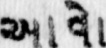

In [15]:
from pathlib import Path
from PIL import Image

WORD_DATASET_DIR = Path(
    r"D:\code material 2.0\akshar-setu-v2\data\words\train\train"
)

sample_path = WORD_DATASET_DIR / train_df.iloc[0]["image_path"]

print("Image path:", sample_path)
print("Exists:", sample_path.exists())
print("Label:", train_df.iloc[0]["text"])

image = Image.open(sample_path).convert("RGB")

print("Image size:", image.size)
display(image)

In [18]:
from transformers import (
    TrOCRProcessor,
    ViTImageProcessor,
    RobertaTokenizer
)

MODEL_NAME = "microsoft/trocr-base-printed"

# Image processor from the TrOCR checkpoint
image_processor = ViTImageProcessor.from_pretrained(MODEL_NAME)

# TrOCR uses the RoBERTa tokenizer
tokenizer = RobertaTokenizer.from_pretrained("roberta-large")

# Manually combine them
processor = TrOCRProcessor(
    image_processor,
    tokenizer
)

print("TrOCR processor created successfully!")
print("Image size:", image_processor.size)
print("Tokenizer:", type(tokenizer).__name__)

[transformers] `ViTImageProcessor` requires torchvision (not installed); falling back to `ViTImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `ViTImageProcessorPil` directly to silence this warning.


TrOCR processor created successfully!
Image size: SizeDict(height=384, width=384, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
Tokenizer: RobertaTokenizer


In [19]:
test_text = "ગુજરાતી ભાષા"

encoded = tokenizer(
    test_text,
    add_special_tokens=True
)

decoded = tokenizer.decode(
    encoded["input_ids"],
    skip_special_tokens=True
)

print("Original:", test_text)
print("Decoded :", decoded)
print("Tokens  :", len(encoded["input_ids"]))

Original: ગુજરાતી ભાષા
Decoded : ગુજરાતી ભાષા
Tokens  : 36


In [20]:
from transformers import VisionEncoderDecoderModel

model = VisionEncoderDecoderModel.from_pretrained(
    MODEL_NAME
)

print("Model loaded!")
print(
    "Parameters:",
    round(sum(p.numel() for p in model.parameters()) / 1e6, 2),
    "M"
)

Loading weights: 100%|██████████| 478/478 [00:00<00:00, 565.93it/s]
[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded!
Parameters: 333.92 M


In [1]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Torch CUDA version:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CUDA device count:", torch.cuda.device_count())

Python: D:\code material 2.0\akshar-setu-v2\.venv\Scripts\python.exe
PyTorch: 2.14.0+cpu
CUDA available: False
Torch CUDA version: None
CUDA device count: 0
